In [14]:
import obspy
from obspy import read
from geopy.distance import geodesic
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime
from obspy.signal.filter import lowpass
from obspy.clients.fdsn.client import Client
import json
import scipy
import glob
import xarray as xr
from matplotlib.colors import LightSource
import cartopy.crs as ccrs         # to plot maps with different projections
import cartopy.feature as cfeature # to plot coastlines, land, borders, etc.
import json
import matplotlib
from matplotlib import colors
from pyproj import Proj
from geopy.distance import geodesic
import pickle
import matplotlib.animation as animation
matplotlib.rcParams['font.family'] = ['Arial']
plt.rcParams.update({'font.size': 14}) 
from math import radians, cos, sin, atan2, sqrt, degrees
import imageio
from itertools import product
import dask
from dask.diagnostics import ProgressBar
with open('/Users/zoekrauss/offshore_eew_modeling/location/PB2002_boundaries.json', 'r') as f:
    plate_boundaries = json.load(f)

In [5]:
# Convert input time series to velocity/acceleration; implement gain correction

def toground_velocity(raw: np.ndarray, fs: float, gain: float, channel: str, p: dict[str, float]) -> np.ndarray:
    """Return v[] as EWP2 ToGround does (minimal implementation)."""
    dt = 1.0 / fs
    q_acc = p["HPFCAcceleration"]
    q_vel_a = p["HPFCVelocityA"]
    q_vel_v = p["HPFCVelocityV"]

    bg_for_accel = 2.0 * gain / (1.0 + q_acc)
    tg_for_accel = dt * gain
    t2b_for_velo = (1.0 + q_vel_a) * dt / 4.0
    bg_for_velo = 2.0 * gain / (1.0 + q_vel_v)

    n = raw.size
    a = np.zeros(n, dtype=np.float64)
    v = np.zeros(n, dtype=np.float64)

    acceleration_input = len(channel) > 1 and channel[1] in {"N", "L"}

    # initial state equivalent
    var_z0 = raw[0]
    var_a0 = 0.0
    var_v0 = 0.0

    # i=0
    if acceleration_input:
        a[0] = (raw[0] - var_z0) / bg_for_accel + q_acc * var_a0
        v[0] = (a[0] + var_a0) * t2b_for_velo + q_vel_a * var_v0
    else:
        a[0] = (raw[0] - var_z0) / tg_for_accel
        v[0] = (raw[0] - var_z0) / bg_for_velo + q_vel_v * var_v0

    # i>=1
    for i in range(1, n):
        dz = raw[i] - raw[i - 1]
        if acceleration_input:
            a[i] = dz / bg_for_accel + q_acc * a[i - 1]
            v[i] = (a[i] + a[i - 1]) * t2b_for_velo + q_vel_a * v[i - 1]
        else:
            a[i] = dz / tg_for_accel
            v[i] = dz / bg_for_velo + q_vel_v * v[i - 1]

    return v

def picker_sta_lta_and_triggers(
    v: np.ndarray,
    fs: float,
    first_sample_time: float,
    p: dict[str, float | int | bool],
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Compute picker high-pass r, STA, LTA, ratio, and trigger times.

    Trigger condition follows PickerTSPModule behavior:
      stabilized && gap-delay-passed && untrigger-window-passed && sta > TrigLev * lta
    """
    dt = 1.0 / fs

    # Picker parameters
    q_raw = float(p["HPFCRaw"])
    t_sta = float(p["TSCTsta"])
    t_lta = float(p["TSCTlta"])
    tau_k = float(p["RICTauK"])

    trig_lev = float(p["TrigLev"])
    trig_dur = float(p["TrigDur"])
    use_trig_stab = bool(p["UseTrigStab"])
    trig_stab_lev = float(p["TrigStabLev"])
    use_trig_gap_delay = bool(p["UseTrigGapDelay"])
    trig_gap_dur = float(p["TrigGapDur"])

    # Exponential smoothing coefficients for STA/LTA updates
    a1_sta = dt / t_sta
    a1_lta = dt / t_lta
    a_sta = 1.0 - a1_sta
    a_lta = 1.0 - a1_lta

    n = v.size
    r = np.zeros(n, dtype=np.float64)
    sta = np.zeros(n, dtype=np.float64)
    lta = np.zeros(n, dtype=np.float64)

    # Saved state (equivalent to "prev_*" values in C++)
    prev_v = 0.0
    prev_r = 0.0
    prev_sta = 0.0
    prev_lta = 0.0

    # Gap behavior at start of process() call
    in_gap = True
    time_gap_delay = 0.0
    if in_gap:
        in_gap = False
        time_gap_delay = first_sample_time + abs(trig_gap_dur)

    # Stabilization is either required (false initially) or disabled (true initially)
    stabilized = not use_trig_stab

    # Holdoff after a trigger to prevent immediate retriggering
    time_untrig = 0.0

    trig_idx: list[int] = []
    trig_time: list[float] = []

    # ----- i = 0 -----
    r[0] = q_raw * prev_r + (v[0] - prev_v)
    cf0 = r[0] ** 2 + tau_k * (v[0] - prev_v) ** 2
    sta[0] = a_sta * prev_sta + a1_sta * cf0
    lta[0] = a_lta * prev_lta + a1_lta * cf0

    # Once stabilized condition is met once, it remains true
    if sta[0] < trig_stab_lev * lta[0]:
        stabilized = True

    t0 = first_sample_time
    if (
        stabilized
        and ((not use_trig_gap_delay) or (t0 > time_gap_delay))
        and t0 > time_untrig
        and sta[0] > trig_lev * lta[0]
    ):
        trig_idx.append(0)
        trig_time.append(t0)
        time_untrig = t0 + trig_dur

    # ----- i >= 1 -----
    for i in range(1, n):
        sample_time = first_sample_time + i * dt
        dv = v[i] - v[i - 1]

        # Picker high-pass of velocity
        r[i] = q_raw * r[i - 1] + dv

        # Characteristic function used for STA/LTA
        cfi = r[i] ** 2 + tau_k * dv ** 2
        sta[i] = a_sta * sta[i - 1] + a1_sta * cfi
        lta[i] = a_lta * lta[i - 1] + a1_lta * cfi

        if sta[i] < trig_stab_lev * lta[i]:
            stabilized = True

        if (
            stabilized
            and ((not use_trig_gap_delay) or (sample_time > time_gap_delay))
            and sample_time > time_untrig
            and sta[i] > trig_lev * lta[i]
        ):
            trig_idx.append(i)
            trig_time.append(sample_time)
            time_untrig = sample_time + trig_dur

    # Ratio is useful for plotting; picker itself uses sta/lta comparison directly
    ratio = np.divide(sta, lta, out=np.zeros_like(sta), where=lta != 0.0)

    return (
        r,
        sta,
        lta,
        ratio,
        np.array(trig_idx, dtype=int),
        np.array(trig_time, dtype=np.float64),
    )

TypeError: 'type' object is not subscriptable

In [10]:
# Read station/channel metadata into Python lists
file_path = '20241205_cape_mendocino.seismic.dat'

network, station, location, channel = [], [], [], []
latitude, longitude, elevation = [], [], []
samplerate, gain, units = [], [], []
azimuth, dip, sensortype = [], [], []

with open(file_path) as f:
    for line in f:
        if not line.strip() or line.startswith("#"):
            continue

        p = line.split(maxsplit=13)
        network.append(p[0])
        station.append(p[1])
        location.append(p[2])
        channel.append(p[3])
        latitude.append(float(p[4]))
        longitude.append(float(p[5]))
        elevation.append(float(p[6]))
        samplerate.append(float(p[7]))
        gain.append(float(p[8]))
        units.append(p[9])
        azimuth.append(float(p[11]))
        dip.append(float(p[12]))
        sensortype.append(p[13].strip())

# Example: find all rows for one station/channel
wanted_station = "BZN"
wanted_channel = "HHZ"

matches = [i for i, (s, c) in enumerate(zip(station, channel))
           if s == wanted_station and c == wanted_channel]

for i in matches:
    print(latitude[i], longitude[i], elevation[i], sensortype[i])

33.4915 -116.667 1301.0 Streckeisen STS-2 G1/Quanterra 330 Linear Phase Be


In [11]:
hypo_lat = 40.374
hypo_lon = -125.022

In [12]:
first_stations=['PETL','WLKR','KCT','KCO','1584B','89101','1023','KSM','1586','1582'] # this from EPIC files

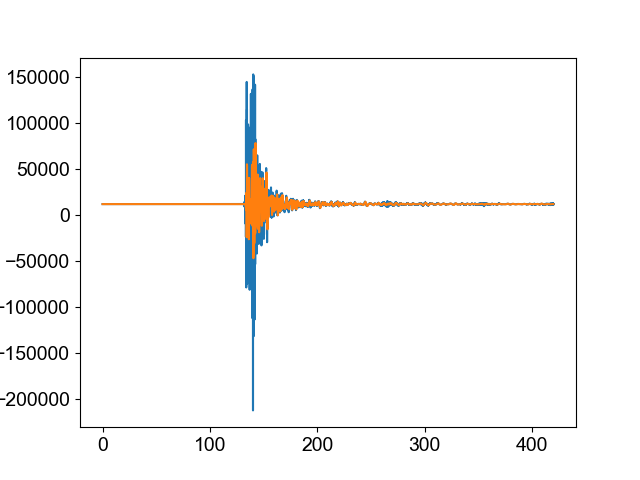

In [15]:
%matplotlib widget
for sta in [first_stations[0]]:
    # all_miniseeds =  glob.glob('/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/mendocino_miniseed_files00/*'+sta+'*' +'HHZ'+'*')

    # if len(all_miniseeds) < 1:
    all_miniseeds =  glob.glob('/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/mendocino_miniseed_files00/*'+sta+'*' +'HNZ'+'*')

    st1 = read(all_miniseeds[0])

    ds_miniseeds = glob.glob('/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/mendocino_first10_downsampled_mseeds/*'+sta+'*' +'HNZ'+'*')
    
    
    st2 = read(ds_miniseeds[0])
    
    fig,ax = plt.subplots(1)
    ax.plot(st1[0].times(),st1[0].data)
    ax.plot(st2[0].times(),st2[0].data)